https://ryuzyproject.tistory.com/213

# **1. 멀티 모달**
- 사람은 사진만 보거나 글만 읽지 않음 > 눈으로 보고, 말을 듣고, 글을, 읽고, 상황을 함께 해석함
- 이런 멀티모달도 위와 비슷하게 서로 다른 형태의 정보를 함께 다룸
    - 이미지: 픽셀, 사물, 색, 위치, 장면
    - 텍스트: 단어, 문장, 의미, 질문
    - 오디오: 음성, 소리, 음악
    - 비디오: 이미지의 시간적 변화 + 경우에 따라 오디오와 함께 처리하기도 함

> Multimodal Learning은 서로 다른 여러 모달리티의 데이터를 함께 학습하는 방식입니다. 예를 들어 이미지와 텍스트를 동시에 입력으로 받아 장면을 설명하거나, 영상과 음성을 함께 활용해 감정을 인식하는 모델이 이에 해당합니다. 각 모달리티가 가진 상호보완적인 정보를 결합함으로써 단일 모달리티보다 더 풍부한 표현과 높은 성능을 기대할 수 있습니다. 최근에는 비전과 언어를 결합한 모델들이 대표적인 성공 사례로 주목받고 있습니다.

___
https://ryuzyproject.tistory.com/214

# **2. CLIP**
CLIP은 이미지와 텍스트를 같은 의미 공간으로 정렬하기 위해 대비 학습(contrastive learning)을 사용하는 대표적인 Pretrained Vision–Language 모델입니다. 이미지 인코더와 텍스트 인코더를 각각 학습시킨 뒤, 올바른 이미지–텍스트 쌍은 임베딩 공간에서 가깝게, 관련 없는 쌍은 멀어지도록 학습함으로써 두 모달리티 간 의미적 대응 관계를 형성합니다. 이 구조 덕분에 별도의 태스크별 학습 없이도 텍스트로 정의한 클래스 설명만으로 이미지를 분류하는 zero-shot 분류가 가능하며, 이미지–텍스트 검색(Text-to-Image, Image-to-Text Retrieval)에 특히 강점을 보입니다. 다만 생성 능력은 없고, 주로 “이해와 정렬”에 초점이 맞춰진 모델이라는 특징을 가집니다. [[논문 바로가기](https://arxiv.org/pdf/2103.00020)]

### **2-1. 표현 정렬과 생성의 차이**
- Dual encoder(CLIP): 이미지와 문장을 독립적으로 벡터화하고 유사도를 비교. 빠른 검색/zero-shot 분류에 적합
- Encoder-decoder(BLIP): 이미지 특징을 참고해서 문장을 토큰단위로 생성. (이미지를 보고 사람처럼 실제 '강아지냐 고양이냐' 수준이 아닌 '풀밭에 앉아있는 강아지'이런식으로 문장을 생성할 수 있음)
- Grounded detection(Grounding DINO): 텍스트 표현을 조건으로 이미지 속 위치나 박스를 찾는 형태의 기술 혹은 모델('벤치에 앉아있는  여자'같은 문장을 주면 이미지에서 '벤치에 앉아있는 여자'에 박스쳐서 나타나게 됨)
- VLM/멀티모달 LLM: 비전 인코더와 언어 모델을 연결해 이미지 기반 질의응답, 추론, 대화를 수행할 수 있음. 모델별 성능과 지원 모달리티는 다를 수 있음(요즘에 이런 종류가 많아짐.)

![정렬, 생성, 위치찾기, 이해와 대화 비교 이미지](./images/ref/01_01.png)

- 인코더: 원본 데이터를 모델이 계산하기 좋은 숫자 특징으로 바꾸는 부분
    - 예) 이미지 인코더는 사진을 받고, 텍스트 인코더는 문장을 받아 벡터로 바꿈
- 임베딩: 데이터의 의미를 숫자 배열(벡터)로 표현한 것. 비슷한 의미를 가진 데이터가 한 방향에 놓이도록 학습함
- 프로젝션: 이미지 인코더와 텍스트 인코더가 만든 서로 다른 특징을 같은 차원의 공통 공간으로 옮기는 변화
- 유사도: 두 벡터가 의미적으로 얼마나 가까운지 나타내는 값

### **2-2. 대비 학습(contrastive learning)**
```
한 배치에 이미지 4장과 각 이미지의 설명 4개가 있음

            문장1   문장2   문장3   문장4
이미지1      높음    낮음    낮음    낮음
이미지2      낮음    높음    낮음    낮음
이미지3      낮음    낮음    높음    낮음
이미지4      낮음    낮음    낮음    높음

```

> 정답에 대한 쌍은 대각선임. 학습할 때 대각선 점수는 높이고, 나머지는 낮추는 방향으로 진행해야함. CLIP은 이미지를 텍스트 검색, 이미지 검색을 모두 수행할 수 있게 학습하게 됨

```
고양이 사진 <> "a photo of a cat"       # 가깝게 학습
고양이 사진 <> "a photo of a banana"    # 멀게 학습
고양이 사진 <> "a photo of a TV"        # 멀게 학습
```

> 매우 많은 이미지-텍스트 쌍으로 학습을 반복하면 모델은 단순 클래스 번호가 아닌 시각적 특징과 언어 의미의 관계를 학습하게 됨

### **2-3. Zero-Shot 분류**
1. 후보 클래스 이름을 문장으로 만듦  예) "a photo of a cat"
2. 후보 문장들의 텍스트 임베딩을 만듦
3. 입력 이미지 임베딩과 각 텍스트 임베딩의 유사도를 비교함
4. 가장 유사한 텍스트를 예측 클래스로 사용함

> Shot은 새로운 작업에서 제공하는 학습 예제 수. 
> 예) Zero-shot은 해당 작업을 위해 정답 예제를 새로 주고 재학습하지 않은 상태에서 수행한다는 뜻
> CLIP에선 클래스 이름을 자연서 prompt로 만들어 비교하기 때문에 별도의 분류기 학습 없이 새로운 후보를 비교할 수 있음



In [5]:
import random
import io
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from datasets import load_dataset
from transformers import AutoProcessor, CLIPModel

d:\OSA\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
SEED = 2026

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cpu


### **2-4. CLIP 학습 원리**
- 배치 대조 손실
    - $S_{ij}=v_i^\top t_j/\tau$
    - 이미지 임베딩($v_i$)와 텍스트 임베딩 $t_j$를 L2 정규화한 뒤, 유사도 행렬 $S_{ij}를 만듦
    - $\tau$sms temporature이며, 구현에선 학습 가능한 logit_scale을 사용
    - 정답 쌍이 대각선에 오도록 이미지에서 > 텍스트와 텍스트에서 > 이미지 교차 엔트로피를 평균내서 학습함

> softmax로 얻은 후보별 점수는 주어진 후보 문장들 사이의 상대적인 값이며, 현실세계의 절재적인 정답 확률로 해석하면 안됨

In [7]:
MODEL_ID = "openai/clip-vit-base-patch32"
DATASET_ID = "clip-benchmark/wds_imagenetv2"
SAMPLE_SIZE = 10

# AutoProcessor: 이미지 리사이즈/정규화와 텍스트 토큰화를 모델에 맞게 처리하도록 객체를 생성
processor = AutoProcessor.from_pretrained(MODEL_ID)
model = CLIPModel.from_pretrained(MODEL_ID).to(DEVICE)
model.eval()

print("CLIP projection dim: ", model.config.projection_dim)

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 27536.75it/s]

CLIP projection dim:  512


In [8]:
dataset = load_dataset(DATASET_ID, split="test")
subset = dataset.shuffle(seed=SEED).select(range(SAMPLE_SIZE))

print(subset)
print("컬럼들: ", subset.column_names)

Dataset({
    features: ['__key__', '__url__', 'cls', 'webp'],
    num_rows: 10
})
컬럼들:  ['__key__', '__url__', 'cls', 'webp']


In [9]:
def to_pil(x):
    if isinstance(x, Image.Image):
        return x.convert("RGB")
    if isinstance(x, dict) and x.get("bytes") is not None:
        return Image.open(io.BytesIO(x["bytes"])).convert("RGB")
    if isinstance(x, str):
        return Image.open(x).convert("RGB")
    raise TypeError(f"지원하지 않는 이미지 타입: {type(x)}")

image_col = "webp" if "webp" in subset.column_names else "image"
label_col = "cls" if "cls" in subset.column_names else "label"

images = [to_pil(x) for x in subset[image_col]]
labels = [int(x) for x in subset[label_col]]
print(labels)

[256, 661, 452, 448, 231, 528, 208, 985, 482, 475]


- 데이터셋(load_dataset)으로 샘플 로드하고, 
- shuffle(seed=2026)으로 재현 가능한 순서 만든 다음, 
- select로 소량(10개)추출함

In [10]:
try:
    from torchvision.models import ResNet50_Weights
    imagenet_names = ResNet50_Weights.DEFAULT.meta["categories"]
except Exception as e:
    raise RuntimeError(
        "ImageNet 클래스 이름을 불러오지 못했습니다. torchvision을 설치하거나 기존 classnames.txt를 사용하세요."
    ) from e

In [ ]:
# imagenet_names # 카테고리만 볼 수 있음

label_names = [imagenet_names[i] for i in labels]
print(label_names) # 10개 확인 가능

text_prompts = [f'a photo of a {name}' for name in label_names]
text_prompts # 문장 만들어진거 확인(클래스를 가지고 어거지로 만든거)

['Newfoundland', 'Model T', 'bonnet', 'birdhouse', 'collie', 'dial telephone', 'Labrador retriever', 'daisy', 'cassette player', 'car mirror']


['a photo of a Newfoundland',
 'a photo of a Model T',
 'a photo of a bonnet',
 'a photo of a birdhouse',
 'a photo of a collie',
 'a photo of a dial telephone',
 'a photo of a Labrador retriever',
 'a photo of a daisy',
 'a photo of a cassette player',
 'a photo of a car mirror']

In [12]:
# enumerate(): 반복 가능한 데이터에 인덱스(번호)를 붙여주는 파이썬 내장 함수
for i, (name, prompt) in enumerate(zip(label_names, text_prompts)):
    print(f'{i:02d} | {name:25s} | {prompt}')

00 | Newfoundland              | a photo of a Newfoundland
01 | Model T                   | a photo of a Model T
02 | bonnet                    | a photo of a bonnet
03 | birdhouse                 | a photo of a birdhouse
04 | collie                    | a photo of a collie
05 | dial telephone            | a photo of a dial telephone
06 | Labrador retriever        | a photo of a Labrador retriever
07 | daisy                     | a photo of a daisy
08 | cassette player           | a photo of a cassette player
09 | car mirror                | a photo of a car mirror


In [13]:
# processor: 모델은 PIL 이미지나 문자열을 그대로 계산하지 못함. 입력을 모델 형식으로 자동으로 바꿔주는 전처리 담당자
# 이미지의 경우 > resize와 pixel 자동 변환 > normalize > 모델 입력 Tensor
# 문장의 경우 > tokenize > token id 변환 > 모델 입력 Tensor

inputs = processor(images=images, text=text_prompts, padding=True, return_tensors="pt").to(DEVICE)

In [14]:
with torch.inference_mode(): 
    outputs = model(**inputs)

In [15]:
image_features = outputs.image_embeds
text_features = outputs.text_embeds

print("image_features type: ", type(image_features))
print("text_features type: ", type(text_features))
print("image_features shape: ", image_features.shape)
print("text_features shape: ", text_features.shape)

image_features type:  <class 'torch.Tensor'>
text_features type:  <class 'torch.Tensor'>
image_features shape:  torch.Size([10, 512])
text_features shape:  torch.Size([10, 512])


### **2-5-1. L2정규화와 코사인 유사도**
벡터의 길이를 1로 만들면 두 벡터의 내적은 코사인 유사도가 됨
```
    x = torch.tensor([[3.0, 4.0]])
    result = F.normalize(x, p=2, dim=1)
```
$\sqrt{3^2 + 4^2} = \sqrt25 = 5$

$3/5, 4/5 = [0.6, 0.8]$

$(0.6)^2 + (0.8)^2 = 1$

- 1에 가까울수록 방향이 비슷함 > 의미적으로 더 잘 맞음
- 0 부근 > 관련성이 약함
- 음수 > 방향이 반대인 경향

### **2-5-2. L2정규화**
벡터의 크기 자체보다 방향, 의미적 방향을 비교하기 위해 사용
- F.normalize(..., p=2): 각 벡터의 길이를 1로 만듦. 두 단위의 내적이 코사인 유사도와 같아짐

```
p=1 L1 노름: 절댓값을 더함
p=2 L2 노름: 제곱해서 더한 뒤 제곱근
p=3 L3 노름: 세제곱해서 더한 뒤 세제곱근
```

![L2정규화와 코사인유사도 이해용 이미지](./images/ref/01_02.png)


In [16]:
import torch.nn.functional as F

In [17]:
image_features = F.normalize(image_features, p=2, dim=-1)
text_features = F.normalize(text_features, p=2, dim=-1)

similarity = image_features @ text_features.T   # .T 안붙이면 에러남, 전치시키기 위해 T 사용
print("similarity tensor shape:", similarity.shape)
print(torch.round(similarity.cpu() * 1000) / 1000)

# PyTorch Tensor → NumPy 배열 변환 (시각화용)
similarity_np = similarity.detach().cpu().numpy()

similarity tensor shape: torch.Size([10, 10])
tensor([[0.2680, 0.1930, 0.1960, 0.1820, 0.2430, 0.1910, 0.2450, 0.1730, 0.1650,
         0.1600],
        [0.1890, 0.3110, 0.2300, 0.1650, 0.2040, 0.2110, 0.2150, 0.1840, 0.1680,
         0.2200],
        [0.1800, 0.1870, 0.2460, 0.2070, 0.1920, 0.1800, 0.2080, 0.2310, 0.1660,
         0.1860],
        [0.2140, 0.2000, 0.2940, 0.3100, 0.2090, 0.2220, 0.2290, 0.2310, 0.1760,
         0.1960],
        [0.2310, 0.2080, 0.2100, 0.1690, 0.2780, 0.1840, 0.2280, 0.2280, 0.1800,
         0.1720],
        [0.1890, 0.2070, 0.2090, 0.1910, 0.1860, 0.3240, 0.1940, 0.2040, 0.2150,
         0.1970],
        [0.2140, 0.1800, 0.2090, 0.1930, 0.2440, 0.1920, 0.2400, 0.1940, 0.1570,
         0.1880],
        [0.1940, 0.1980, 0.2550, 0.2180, 0.2280, 0.2070, 0.2020, 0.3230, 0.1880,
         0.2070],
        [0.1550, 0.2190, 0.2320, 0.1910, 0.1870, 0.2450, 0.1720, 0.1950, 0.2680,
         0.2070],
        [0.1940, 0.1920, 0.2250, 0.1940, 0.2020, 0.2030, 0.2120

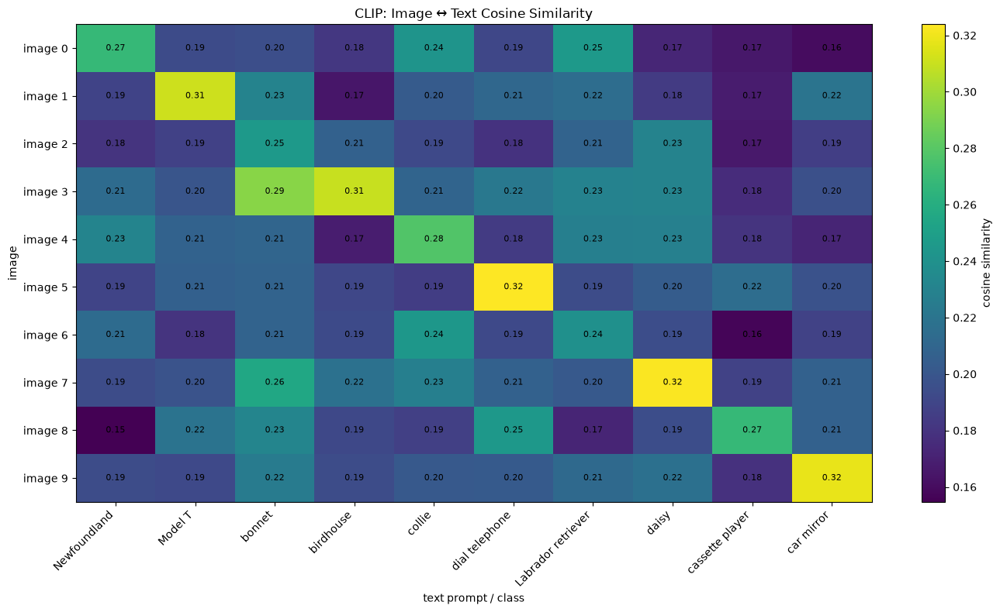

In [18]:
fig, ax = plt.subplots(figsize=(14, 8))
im = ax.imshow(similarity_np, aspect="auto")
fig.colorbar(im, ax=ax, label="cosine similarity")

ax.set_xticks(range(len(images)))
ax.set_xticklabels(label_names, rotation=45, ha="right")
ax.set_yticks(range(len(images)))
ax.set_yticklabels([f"image {i}" for i in range(len(images))])

ax.set_xlabel("text prompt / class")
ax.set_ylabel("image")
ax.set_title("CLIP: Image ↔ Text Cosine Similarity")

for i in range(len(images)):
    for j in range(len(images)):
        ax.text(
            j, i,
            f"{similarity_np[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.tight_layout()
plt.show()

- 각 행은 이미지, 각 열은 그 이미지들에서 만든 클래스 문장
- 샘플 순서를 맞췄으므로 대각선 값이 상대적으로 높으면 정답 이미지-문장 매칭이 잘 된 것이라 보면 됨
- 정확한 zero-shot 분류 평가를 하려면 1000개의 전체 클래스에 대해 비교를 하면 좋음
- 클립은 어쨋든 생성형은 아니고 문장과 비교를 해서 위치가 비슷한지 평가하는 모델이기 때문에~~

> CLIP은 '무엇과 관련 있는가?'에 강하지만, 물체의 정확한 위치를 직접 출력하지 않고, 자연어 문장을 생성하는것도 주목적이 아님!

![마크다운 이해용 이미지](./images/ref/01_03.png)

___
# **3. DINO**
AI 분야에서 DINO라는 이름은 서로 다른 유명 연구에 쓰임

1. DINO(Self-Distillation with No Labels): Meta 계열의 자기지도 학습 비전 표현 학습 연구 (DINOv2, DINOv3 계열)
2. DINO(DETR with Improved DeNoising Anchor Noxes): DETR 계열 객체 탐지 모델 [[논문보기](https://arxiv.org/pdf/2203.03605)]
    - DETR: Transformer와 object query를 이용해 객체 탐지를 set prediction 문제로 바꿈. anchor 설계와 NMS 중심의 전통적인 파이프라인을 크게 단순화 [[논문보기](https://arxiv.org/pdf/2005.12872)]
        - object query: Decoder에 들어가는 학습 가능한 객체 슬롯
            - ex) 100개의 query가 있다면 각 query는 이미지 특징을 보면서 '내가 찾고자하는 객체가 있는가?' 있다면 '어떤 클래스이고 박스는 어디에 있나?'를 학습
    - DETR 계열의 느린 수렴과 query 학습 문제를 개선하기 위해 denoising training, 더 좋은 query/reference 설계 등 사용
        - denoising training: 정답 label/box에 일부 노이즈를 넣은 query를 추가하고, 모델이 원래 정답을 복원하도록 학습
    - Grounding DINO: DINO 계열 detector에 언어 조건을 결합
        - DETR: 이미지 > 객체가 어디에 있는지 찾음
        - DINO: 이미지 > DETR보다 더 안정적이고 효율적으로 객체를 찾음
        - Grounding DINO: 이미지 + 텍스트 > 이 텍스트가 가리키는 객체가 어디에 있는지 찾음
            - ex) a cat. a remote control. 을 넣게되면 모델은 클래스 번호만 출력하는것이 아닌 텍스트 표현과 관련 있는 이미지 영역을 찾아 박스로 변환(label + score + bounding box의 형태)

![DINO 설명요약](./images/ref/01_04.png)

In [19]:
# 이미지 1장과 후보 클래스 4개의 문장을 CLIP으로 비교해 클래스별 상대 점수 확인
candidate_labels = ["cat", "dog", "remote control", "car"]
candidate_prompts = [f"a photo of a {label}" for label in candidate_labels]
example_inputs = processor(images=images[0], text=candidate_prompts, padding=True, return_tensors="pt").to(DEVICE)
with torch.inference_mode():
    clip_out = model(**example_inputs)
relative_scores = clip_out.logits_per_image.softmax(dim=-1)[0].cpu()
for label, score in sorted(zip(candidate_labels, relative_scores.tolist()), key=lambda x: -x[1]):
    print(f"{label:20s} {score:.3f}")

dog                  0.941
cat                  0.050
remote control       0.009
car                  0.000


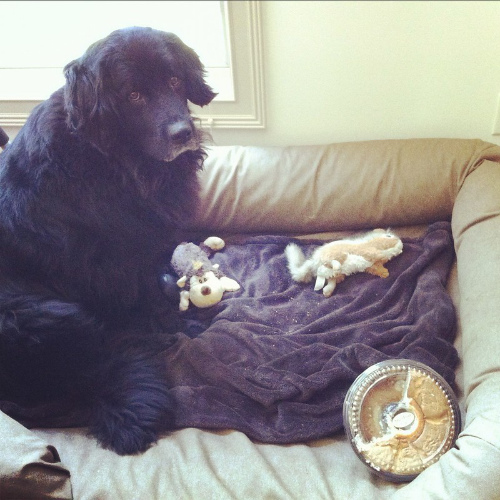

In [20]:
# CLIP 분류에 사용한 첫 번째 이미지 확인
images[0]

In [21]:
# CLIP 모델에 입력한 후보 클래스 문장 목록 확인
candidate_prompts

['a photo of a cat',
 'a photo of a dog',
 'a photo of a remote control',
 'a photo of a car']

In [22]:
# Grounding DINO 환경 준비
import requests
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection

GROUNDING_MODEL_ID = "IDEA-Research/grounding-dino-tiny"
device = DEVICE
print("device:", device)

device: cpu


In [23]:
# 사전 학습된 Grounding DINO의 Processor와 모델을 불러오고 평가 모드로 설정

# Grounding DINO: 텍스트로 대상 객체의 박스를 찾고, 박스를 분할 모델에 전달해 픽셀 단위 마스크를 얻는 파이프라인
# 작은 객체, 가림, 모호한 지시문, 도메인 차이에서 실패할 수 있어 결과 검증이 필요
processor = AutoProcessor.from_pretrained(GROUNDING_MODEL_ID)

# AutoModelForZeroShotObjectDetection: 사전에 고정한 클래스 ID만 사용하는 대신 텍스트 조건으로 탐지
# 최근에 오토로 하는게 젤 좋다함.. 머가 달라질 수 있고 머가 어떻다 하셨는데..
model = AutoModelForZeroShotObjectDetection.from_pretrained(GROUNDING_MODEL_ID).to(device)

model.eval()

Loading weights: 100%|██████████| 978/978 [00:00<00:00, 1030.64it/s]


GroundingDinoForObjectDetection(
  (model): GroundingDinoModel(
    (backbone): GroundingDinoConvModel(
      (conv_encoder): GroundingDinoConvEncoder(
        (model): SwinBackbone(
          (swin): SwinModel(
            (embeddings): SwinEmbeddings(
              (patch_embeddings): SwinPatchEmbeddings(
                (projection): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
              )
              (norm): LayerNorm((96,), eps=1e-05, elementwise_affine=True, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (encoder): SwinEncoder(
              (layers): ModuleList(
                (0): SwinStage(
                  (blocks): ModuleList(
                    (0): SwinLayer(
                      (attention): SwinAttention(
                        (q_proj): Linear(in_features=96, out_features=96, bias=True)
                        (k_proj): Linear(in_features=96, out_features=96, bias=True)
                        (v_proj): Linear(

In [24]:
# 이미지 및 텍스트 전처리
# COCO 이미지와 탐지할 객체 문장을 준비하고 모델 입력 Tensor로 변환

image_url = "http://images.cocodataset.org/val2017/000000039769.jpg"

image = Image.open(
    __import__("io").BytesIO(requests.get(image_url, timeout=10).content)
).convert("RGB")

text_labels = [['a cat', 'a remote control']]

inputs = processor(images=image, text=text_labels, return_tensors="pt").to(device)

print({k: tuple(v.shape) for k, v in inputs.items() if hasattr(v, 'shape')})

{'input_ids': (1, 9), 'token_type_ids': (1, 9), 'attention_mask': (1, 9), 'pixel_mask': (1, 800, 1066), 'pixel_values': (1, 3, 800, 1066)}


위 출력값 해석

![위 코드 출력값 해석 표](./images/ref/01_05.png)

In [25]:
# Grounding DINO로 객체를 탐지하고 후처리하여 클래스명·점수·Bounding Box 출력

with torch.inference_mode():
    outputs = model(**inputs)

# threshold: 객체 후보를 박스로 인정할것인지
# text_threshold: 해당 영역과 텍스트 표현의 연결이 충분히 강하지
# 너무 낮으면 오탐이 늘고, 너무 높이면 실제 객체도 놓칠 수 있음
results = processor.post_process_grounded_object_detection(
    outputs,
    threshold=0.35,
    text_threshold=0.25,
    target_sizes=[(image.height, image.width)],
    text_labels=text_labels,
)

result = results[0]

detected_labels = result.get("text_labels", result.get("labels"))

print("detections:", len(result["boxes"]))

for box, score, label in zip(
    result["boxes"],
    result["scores"],
    detected_labels
):
    box = [round(x, 1) for x in box.tolist()]
    print(
        f"{label} | score={score.item():.3f} | box={box}"
    )

detections: 3
a cat | score=0.488 | box=[344.5, 23.2, 637.3, 374.5]
a cat | score=0.450 | box=[12.2, 52.0, 316.9, 472.6]
a remote control | score=0.465 | box=[38.8, 70.1, 176.7, 118.0]


d:\OSA\venv\Lib\site-packages\transformers\models\grounding_dino\processing_grounding_dino.py:94: FutureWarning: The key `labels` is will return integer ids in `GroundingDinoProcessor.post_process_grounded_object_detection` output since v4.51.0. Use `text_labels` instead to retrieve string object names.
  warnings.warn(self.message, FutureWarning)


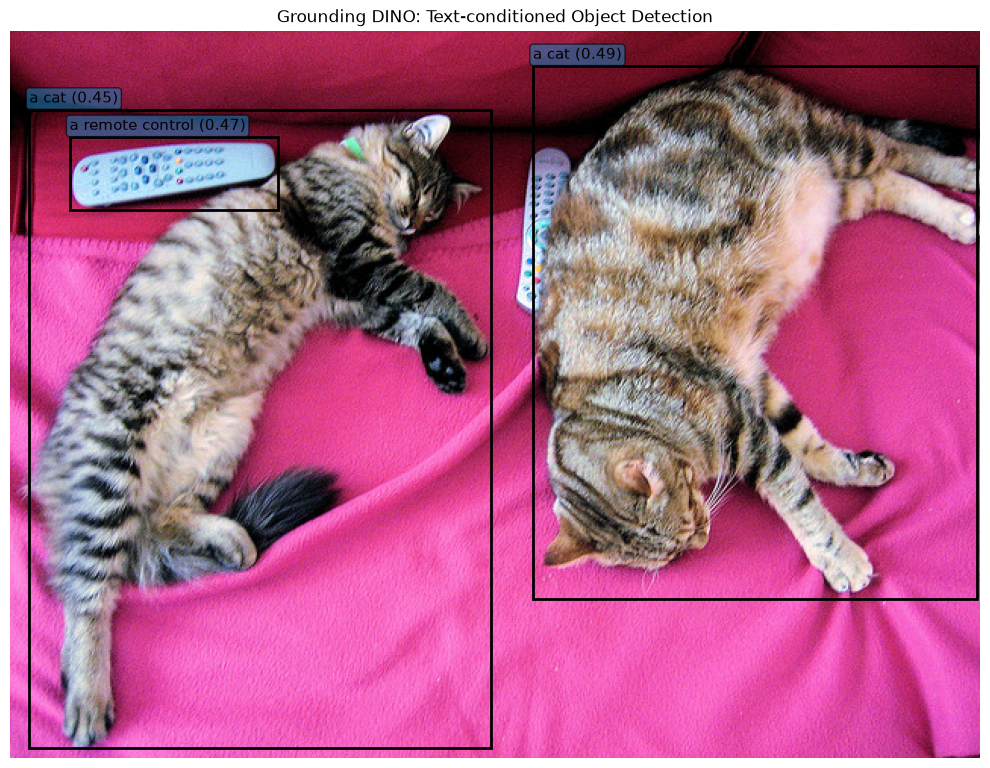

In [26]:
fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(image)

detected_labels = result.get("text_labels", result.get("labels"))

for score, box, label in zip(
    result["scores"].detach().cpu(),
    result["boxes"].detach().cpu(),
    detected_labels
):
    x1, y1, x2, y2 = box.tolist()

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=2,
        fill=False
    )
    ax.add_patch(rect)

    ax.text(
        x1,
        max(0, y1 - 5),
        f"{label} ({score.item():.2f})",
        fontsize=11,
        bbox=dict(alpha=0.6, boxstyle="round,pad=0.2")
    )

ax.axis("off")
ax.set_title("Grounding DINO: Text-conditioned Object Detection")
plt.tight_layout()
plt.show()

___
# **4. BLIP**
- CLIP은 이미지와 텍스트를 같은 임베딩 공간에 잘 정렬하지만 기본적으로 텍스트 생성 모델은 아님
- BLIP은 이미지-텍스트 정렬뿐 아니라 이미지 캡셔닝, 이미지-텍스트 매칭, VQA 같은 이해/생성 작업을 함께 다루는 방향으로 발전. 웹에서 크롤링하여 모은 이미지-텍스트 쌍의 노이즈를 그대로 믿지 않고, 모델이 캡션을 새엉하고 필터링하여 데이터를 개선하는 CapFit 방식 사용 [[논문보기](https://arxiv.org/pdf/2201.12086)]

![BLIP 참고 이미지](./images/ref/01_06.png)

### **4-1. BLIP 구조**
BLIP은 하나의 Transformer 계열을 상황에 따라 다르게 사용해 아래와 같은 특징을 가지고 있음
- Image encoder: 이미지를 시각 특징으로 변환
- Text encoder: 텍스트를 읽고 이미지-텍스트 정렬/매칭에 활용
- Image-grounded text decoder: 이미지 특징을 cross-attention으로 보면서 토큰을 생성

> '이 이미지를 문장으로 어떻게 설명할까'를 수행할 수 있음

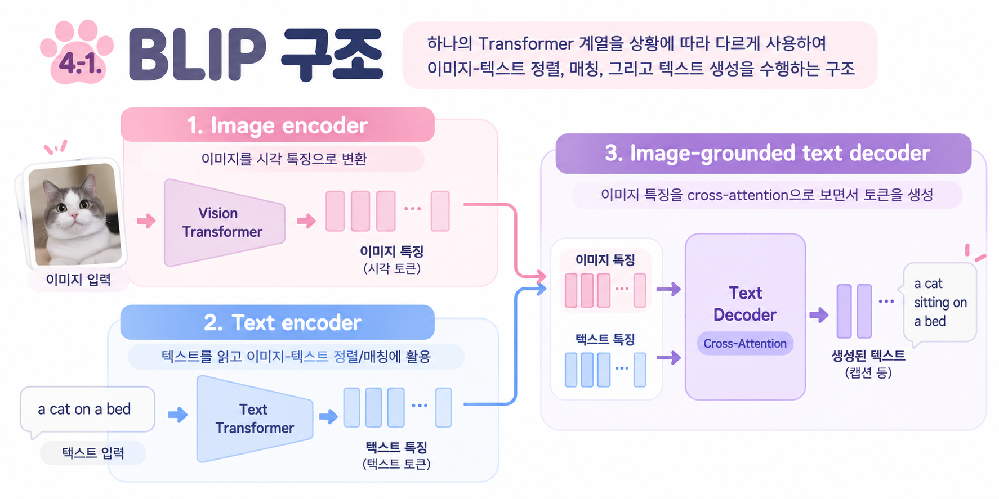

In [27]:
# 탐지된 객체의 Bounding Box 좌표와 신뢰도(Score)를 확인하고 이미지 범위 내에 있는지 검증

print("image size (W,H):", image.size)

for idx, (box, score) in enumerate(zip(result["boxes"], result["scores"])):
    x1, y1, x2, y2 = [float(v) for v in box.cpu().tolist()]
    valid = (0 <= x1 <= x2 <= image.width) and (0 <= y1 <= y2 <= image.height)
    print(f"{idx}: score={float(score):.3f}, box={[round(x1), round(y1), round(x2), round(y2)]}, in_bounds={valid}")

image size (W,H): (640, 480)
0: score=0.488, box=[345, 23, 637, 375], in_bounds=True
1: score=0.450, box=[12, 52, 317, 473], in_bounds=True
2: score=0.465, box=[39, 70, 177, 118], in_bounds=True


### **4-2. cross-attention**
- self-attention: 같은 입력 내부의 참고
- cross-attention: 한 종류의 표햔이 다른 종류의 표현을 참고. BLIP의 경우 텍스트 생성기는 문장을 만들면서 이미지 특징을 cross-attention으로 바라볼 수 있음(그래서 다른 문장들과 비교를 하고, 다른 표현을 참고하며 학습할땐 거리를 조정하며 처리를하고 그 거리를 계산해서 특정 이미지를 설명할 수 있게 함)

In [28]:
# 사전 학습된 BLIP 이미지 캡셔닝 모델과 Processor를 불러오고 평가 모드로 설정

import requests
import torch
from PIL import Image
from transformers import AutoProcessor, BlipForConditionalGeneration

BLIP_MODEL_ID = "Salesforce/blip-image-captioning-base"
processor = AutoProcessor.from_pretrained(BLIP_MODEL_ID)
model = BlipForConditionalGeneration.from_pretrained(BLIP_MODEL_ID).to(device)
model.eval()

Loading weights: 100%|██████████| 473/473 [00:00<00:00, 40290.53it/s]


BlipForConditionalGeneration(
  (vision_model): BlipVisionModel(
    (embeddings): BlipVisionEmbeddings(
      (patch_embedding): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
    )
    (encoder): BlipEncoder(
      (layers): ModuleList(
        (0-11): 12 x BlipEncoderLayer(
          (self_attn): BlipAttention(
            (dropout): Dropout(p=0.0, inplace=False)
            (qkv): Linear(in_features=768, out_features=2304, bias=True)
            (projection): Linear(in_features=768, out_features=768, bias=True)
          )
          (layer_norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
          (mlp): BlipMLP(
            (activation_fn): GELUActivation()
            (fc1): Linear(in_features=768, out_features=3072, bias=True)
            (fc2): Linear(in_features=3072, out_features=768, bias=True)
          )
          (layer_norm2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        )
      )
    )
    (post_layernorm): Laye

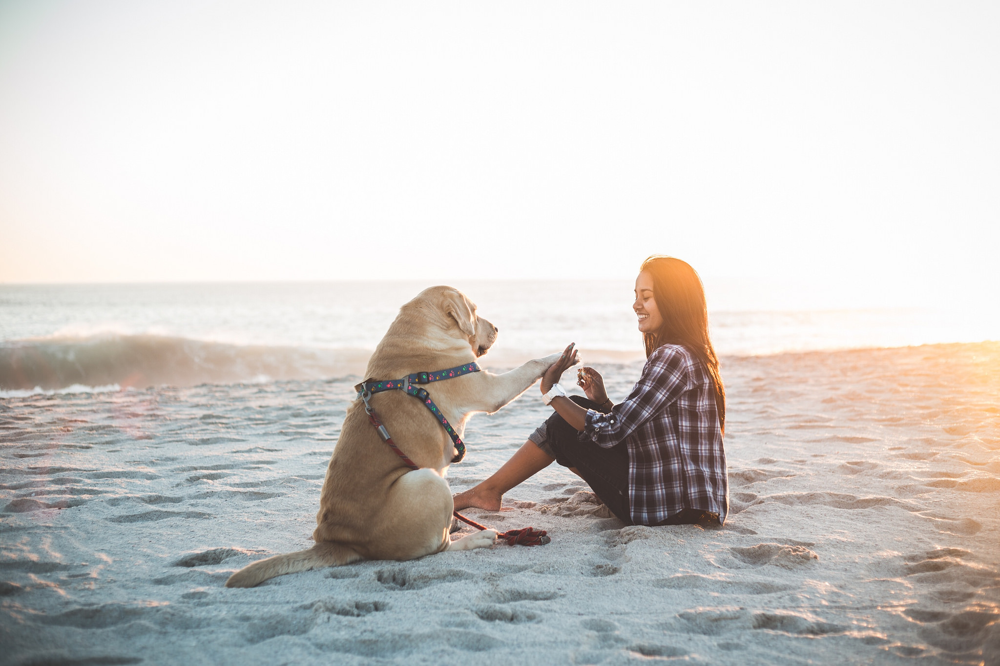

In [29]:
# BLIP 이미지 캡셔닝에 사용할 테스트 이미지를 다운로드하고 화면에 출력
image_url = "https://storage.googleapis.com/sfr-vision-language-research/BLIP/demo.jpg"
image = Image.open(io.BytesIO(requests.get(image_url, timeout=30).content)).convert("RGB")
display(image)

In [30]:
# 이미지 캡션 생성: # 이미지를 BLIP 입력 Tensor로 변환하고 텍스트를 생성한 뒤 디코딩하여 캡션 출력
inputs = processor(images=image, return_tensors="pt").to(device)

with torch.inference_mode():
    # 최대 30개의 새 토큰을 생성하며 토큰을 생성함(30단어 아니고 토큰임)
    generated_ids = model.generate(**inputs, max_new_tokens=30)

# batch_decode: 토큰ID를 읽을 수 있는 문자열로 바꿈. 모델이 영어 중심으로 학습되어 한국어 문장을 바로 기대하긴 어려움!
caption = processor.batch_decode(generated_ids, skip_special_tokens=True)[0].strip()
print("caption:", caption)

caption: a woman sitting on the beach with her dog


>> 전체 흐름을 보는게 중요함!

___
# **5. BLIP-2**
BLIP-2는 이미지와 대형 언어모델(LLM)을 효율적으로 연결하기 위해 설계된 Vision-Language 모델로, 기존 BLIP과 달리 이미지 인코더와 LLM을 직접 미세조정하지 않고, 그 사이에 Q-Former(Querying Transformer)라는 중간 모듈을 두어 두 모델을 연결하는 구조를 사용합니다. 이미지에서 추출한 시각 특징을 Q-Former가 소수의 학습 가능한 쿼리 벡터로 압축하고, 이를 LLM이 이해할 수 있는 형태로 변환하여 텍스트 생성에 활용합니다. 이 방식은 대규모 LLM을 그대로 유지하면서도 이미지 정보를 효과적으로 주입할 수 있어, 이미지 캡셔닝·VQA·멀티모달 질의응답 등에서 강력한 성능을 보이면서도 학습 비용을 크게 줄인 것이 핵심 특징입니다. [[논문보기](https://arxiv.org/pdf/2301.12597)]

### **5-1. BLIP와 BLIP2의 차이점**

### BLIP
- 시각, 언어 이해/생성 통합 학습
- 캡셔닝, VQA, Cross-Attention
- 이미지 특징을 활용해 텍스트 생성

### BLIP2
- 기존 비전 모델과 기존 LLM 연결
- Q-Former, Query Token, 동결된 모델
- 이미지 특징 > Q-Former -> 연결계층 -> LLM 

### **5-2. Vision Encoder**
영상을 수많은 특징 벡터로 정리

```
영상 : 높이 * 너비 * 3(RGB)
예시) 
영상에서 256개 위치의 특징 만들었다 했을 때
영상 > Vision Encoder > [특징1(1000개)] [특징2(1000개)] ... [특징256(1000개)]   # (1000개)는 그냥 예시임
```

위 특징들을 그대로 LLM에 넣을 수 없음
- 시각 특징과 언어 모델의 벡터 차원과 표현 공간이 다를 수 있음
- 모든 시각 특징을 그대로 전달하면 계산량과 입력 길이가 커짐
- 문장을 생성할 때 필요한 시각 정보가 무엇인지 선별하기 어려움

> BLIP-2는 이를 해결하기 위해 정해진 수의 학습 가능한 Query Token을 이용함, 대표적인 BLIP2 설정은 32개의 Query Token을 사용함

![흐름 정리](./images/ref/01_07.png)

### **5-3. Q-Former**
- 이미지의 특징 준비
Vision Encoder가 영상을 분석해 여러 특징을 만들어 둠.

2. Query Token 32개를 준비
Q-Formwe 안에는 처음부터 학습 가능한 32개의 벡터가 있음. 각각은 고정된 문장이나 특정물체를 의미하진 않음

3. Cross-Attention으로 이미지 특징을 참고
각 Query는 이미지 특징들 중 어떤 부분을 얼마나 참고할지 Attention 가중치를 계산
```
[특징1(1000개)] [특징2(1000개)] ... [특징256(1000개)] 각 Cross Attention

    [Query 1] [Query 2] ... [Query 32]

    [출력 1] [출력 2] ... [출력 32]
```

4. Query끼리도 정보를 주고받기
Q-Former의 Self-Attention을 통해 Query간 정보 교환. Cross-Attention은 이미지 특징을 참고, Aelf-Attention은 Query 표현들 사이의 관계를 계산

5. LLM이 사용할 형태로 전달
Q-Former의 출력은 필요한 경우 Linear Projection을 거쳐 LLM의 임베딩 차원으로 변환. 이후 LLM이 이 정보를 조건으로 문장 생성

> Q-Former는 이미지 전체를 '문장으로 번역'하는 것이 아니라, 이미지 특징에서 필요한 정보를 추출해 언어 모델과 연결하는 모듈임


### **5-5. Query, Key, Value**
BLIP-2 Q-Former의 이미지 Cross-Attention에서 개념적으로 생성
- Q(Query): Q-Former의 Query 표현에서 생성
- K(Key): 이미지 인코더가 만든 시각 특징에서 생성
- V(Value): 이미지 인코더가 만든 시각 특징에서 생성

1. Q와 K의 내적: 어떤 이미지 특징을 얼마나 참고할지 점수를 계산
2. Softmax: 각 특징에 대한 참고 비중을 만듦
3. 가중치 *V: 시각 특징들을 가중합해 Query 출력을 업데이트  

In [31]:
import torch
import torch.nn.functional as F

In [33]:
# 3개 이미지 위치가 가진 특징(각 위치마다 2개 숫자)
image_keys = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
image_values = torch.tensor([[10.0, 0.], [0., 20.], [10., 20.]])
query = torch.tensor([[1., 0.]])

# 전치도 시키고... 제곱도 하고..
scores = (query @ image_keys.T) / (image_keys.shape[-1] ** 0.5)
weights = F.softmax(scores, dim=-1)
summary = weights @ image_values

print('이미지 특징별 attention 점수: ', scores.round(decimals=3))
print('참고 비중: ', weights.round(decimals=3))
print('가중합 결과: ', summary.round(decimals=3))
print('참고 비중의 합: ', weights.sum())

이미지 특징별 attention 점수:  tensor([[0.7070, 0.0000, 0.7070]])
참고 비중:  tensor([[0.4010, 0.1980, 0.4010]])
가중합 결과:  tensor([[ 8.0220, 11.9780]])
참고 비중의 합:  tensor(1.)


### **5-6. BLIP-2 실습**
- 권장: CUDA GPU가 있는 환경. 모델이 커져 CPU에선 매우 느리거나 메모리가 부족할 수 있음
- 모델을 양자화하는 실습도 필요할 수 있음

### 5-6-1. 모델 양자화
- 모델이 사용하는 숫자의 정밀도를 낮춰 메모리 사용량을 줄이고, 경우에 따라 추론 속도를 높이는 기술
- 예시) FP16으로 저장된 가중치를 INT8이나 4비트 형태로 바꾸면 더 적은 메모리로 모델 실행
```
weights = [0.123456, -0.123456, 0.567883] 이걸 FP32, FP16, INT8, INT4로 표현한다면?

파라미터가 70억개가 있는 모델의 경우 가중치를 계산하면?
FP32: 32비트/4바이트  > 28GB
FP16: 16비트/2바이트  > 14GB
UNT8: 8비트/1바이트   > 7GB
UNT4: 4비트/0.5바이트 > 3.5GB
```

![float16과 float32](./images/ref/01_08.png)
![float16과 float32 비교](./images/ref/01_09.png)
![실수 100만개 저장시 메모리 예시](./images/ref/01_10.png)

In [ ]:
import torch
from PIL import Image
from io import BytesIO
import requests
from transformers import Blip2Processor, Blip2ForConditionalGeneration

# BLIP-2 모델 지정
BLIP2_MODEL_ID = "Salesforce/blip2-opt-2.7b"
# GPU는 float16(2Byte), CPU는 float32(4Byte)
# 메모리 사용량과 연산 정밀도를 고려한 설정
blip2_dtype = torch.float16 if DEVICE == "cuda" else torch.float32

# 이미지와 텍스트를 모델 입력 형태로 변환할 Processor
# BLIP2는 이미지와 텍스트 함께 입력받을 수 있음(두 종류 전처리 필요)
# 이미지: 이미지 크기 조정. RGB 이미지 처리. 픽셀 값 텐서로 변환. 정규화 수행
# 텍스트: Tokenizer 이용해 토큰 ID로 변환
blip2_processor = Blip2Processor.from_pretrained(BLIP2_MODEL_ID)
# 사전학습 모델을 지정된 자료형으로 불러와 장치로 이동
# Blip2ForConditionalGeneration: 모델 클래스임. 이미지나 질문 증의 입력을 조건으로 텍스트 생성
blip2_model = Blip2ForConditionalGeneration.from_pretrained(
    BLIP2_MODEL_ID, torch_dtype=blip2_dtype
).to(DEVICE)
blip2_model.eval()
print("BLIP-2 device:", DEVICE)

d:\OSA\venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\sdesi\.cache\huggingface\hub\models--Salesforce--blip2-opt-2.7b. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

![왜 멀티모달에서 CLIP, DINO, BLIP가 나온거지?](./images/ref/01_11.png)
![그럼 이거 배우면 뭐 할 수 있는데?](./images/ref/01_12.png)

In [ ]:
blip2_url = "https://storage.googleapis.com/sfr-vision-language-research/BLIP/demo.jpg"
blip2_resp = requests.get(blip2_url, timeout=30)
blip2_resp.raise_for_status()
blip2_image = Image.open(BytesIO(blip2_resp.content)).convert("RGB")
display(blip2_image)
print("이미지 크기:", blip2_image.size)

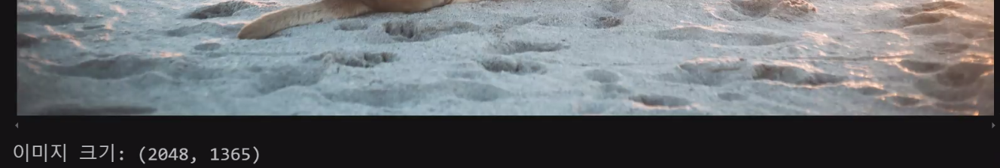

In [ ]:
blip2_caption_inputs = blip2_processor(images=blip2_image, return_tensors="pt").to(
    DEVICE, blip2_dtype
)
with torch.inference_mode():
    blip2_caption_ids = blip2_model.generate(
        **blip2_caption_inputs,
        max_new_tokens=35,
        do_sample=False,
    )
print("캡셔닝:", blip2_processor.batch_decode(blip2_caption_ids, skip_special_tokens=True)[0].strip())

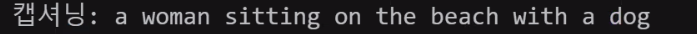

### 5-7. VQA
- Visual Question Answering
- 이미지와 질문을 함께 입력해 답변을 생성하는 작업
- BLIP-2 OUT 모델은 영어 질문을 우선 사용
- Salesforce/blip-out-2.7b는 VQA 전용으로 최적화된 모델이 아니므로, 질문 형식에 따라 엉뚱한 답 할 수 있음

In [ ]:
def ask_blip2(question, image=blip2_image, max_new_tokens=30):
    prompt = f"Question: {question} Answer:"
    inputs = blip2_processor(images=image, text=prompt, return_tensors="pt").to(
        DEVICE, blip2_dtype
    )
    with torch.inference_mode():
        ids = blip2_model.generate(
            **inputs, max_new_tokens=max_new_tokens, do_sample=False,
            num_beams=3
        )
    decoded = blip2_processor.batch_decode(ids, skip_special_tokens=True)[0].strip()
    if decoded.startswith(prompt):
        decoded = decoded[len(prompt):].strip()
    return decoded

questions = [
    "What animal is in the picture?",
    "Where is the dog sitting?",
    "What color is the dog?",
]
for question in questions:
    print("질문:", question)
    print("답변:", ask_blip2(question))
    print("-" * 50)

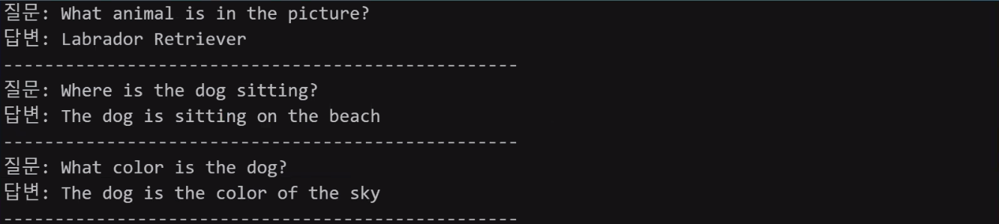

In [ ]:
print("Q-Former 클래스:", type(blip2_model.qformer).__name__)
print("Query Token 텐서 크기:", tuple(blip2_model.query_tokens.shape))
print("Query Token 개수:", blip2_model.query_tokens.shape[1])
print("Q-Former hidden size:", blip2_model.config.qformer_config.hidden_size)
print("Vision hidden size:", blip2_model.config.vision_config.hidden_size)
print("LLM hidden size:", blip2_model.config.text_config.hidden_size)
print("연결 계층:", blip2_model.language_projection)

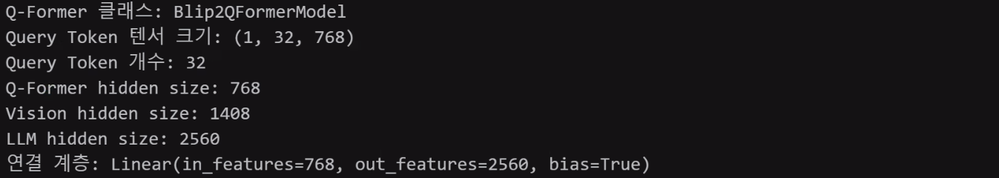

### 총 정리(강사님 말씀 요약)

![정리용 이미지](./images/ref/01_13.png)